# RoadScan — improve detection and inspect generalization

**Question:** can more eligible training images, a stronger detector and higher resolution improve road-damage detection without using test scores for tuning?

We keep the development images from notebooks 04–05. Japan, India and Czech remain the training countries. China remains an unseen-country **development** set. USA and the previous in-domain test stay excluded from training and are not evaluated here. Their earlier scores have already been viewed, so they are historical benchmarks, not fresh blind evidence. A new Saudi test is required for local claims.

The 92% request is recorded as an **aspirational mAP50 target on each development domain**, not as a promised result or an accuracy number. We also report mAP50–95, per-class AP, precision, recall and F1. A high score for one class cannot hide a weak class.

The experiment changes model, training duration and training sample size together. It compares complete training pipelines; it is not an architecture-only ablation. Earlier ResNet scores are historical because its training sample differs.

References: [YOLO26](https://docs.ultralytics.com/models/yolo26/), [training settings](https://docs.ultralytics.com/modes/train/), [RDD classes](https://github.com/sekilab/RoadDamageDetector).

## 1. Environment and experiment settings

Use the same pinned Ultralytics release. Kaggle already provides PyTorch. All meaningful settings are collected here. Training has a fixed epoch plan, early stopping and saved checkpoints; no short wall-time setting changes the learning-rate schedule or planned epoch count.

Phase 1 trains YOLO26s at 768 pixels for at most 90 epochs. Phase 2 starts from its best checkpoint and fine-tunes at 960 pixels for at most 20 epochs, with a smaller learning rate and no Mosaic. This will take hours, not minutes. Early stopping may shorten either phase. A single GPU and conservative batches keep the run simple and limit memory use.

In [1]:
import subprocess
import sys
from pathlib import Path

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'ultralytics==8.4.177', 'ImageHash==4.3.2'
])

import gc
import hashlib
import json
import random
import shutil
import time
from concurrent.futures import ThreadPoolExecutor

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from PIL import Image, ImageDraw
from sklearn.neighbors import NearestNeighbors
from torchvision.ops import box_iou
from ultralytics import YOLO

SEED = 42
CLASSES = ['D00', 'D10', 'D20', 'D40']
TARGET_MAP50 = 0.92
TRAIN_SIZE = 768
EVAL_SIZE = 960
EPOCHS = 90
FINETUNE_EPOCHS = 20
BATCH = 8

OUT = Path('/kaggle/working/roadscan_v2')
OUT.mkdir(exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), 'Select a Kaggle GPU before running.'
print('GPU:', torch.cuda.get_device_name(0))
print('Ultralytics:', __import__('ultralytics').__version__)
(OUT / 'requirements.txt').write_text('ultralytics==8.4.177\nImageHash==4.3.2\n')
(OUT / 'environment.txt').write_bytes(
    subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'])
)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 5.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
Ultralytics: 8.4.177


18108

## 2. Restore the previous audit and fixed development splits

Attach the output of notebook 05 and the original roadscan-yolo dataset. We read saved manifests and training logs, not previous test predictions or scores. Test image paths are used only to prevent overlap. No test annotation is opened by this notebook.

In [2]:
previous = list(Path('/kaggle/input').rglob('recovery_provenance.json'))
assert len(previous) == 1, 'Attach notebook 05 output exactly once.'
PREVIOUS = previous[0].parent

roots = [p.parent.parent for p in Path('/kaggle/input').rglob('train/images')
         if (p.parent.parent / 'train/labels').is_dir()]
assert len(roots) == 1, 'Attach the original roadscan-yolo dataset.'
SOURCE = roots[0]

def current_path(old_path):
    relative = str(old_path).split('/RoadScan_yolo/', 1)[1]
    return str(SOURCE / relative)

def load_manifest(name):
    table = pd.read_csv(PREVIOUS / (name + '_manifest.csv'))
    table['path'] = table['path'].map(current_path)
    table['label'] = table['label'].map(current_path)
    return table

in_dev = load_manifest('in_domain_dev')
china_dev = load_manifest('china_dev')
dev = load_manifest('development')
locked_paths = pd.concat([
    load_manifest('in_domain_test')[['path']],
    load_manifest('us_external')[['path']]
], ignore_index=True)

old_checkpoint = PREVIOUS / 'runs/E2_nano_standard/weights/best.pt'
assert old_checkpoint.is_file(), 'Previous selected detector is missing.'
assert len(dev) == 1000, 'Development manifest changed; review before training.'
print('Previous outputs:', PREVIOUS)
print('Source dataset:', SOURCE)
print('Development:', len(in_dev), 'in-domain,', len(china_dev), 'China')
print('Locked test images excluded:', len(locked_paths))


Previous outputs: /kaggle/input/notebooks/rimasabunasser/05-roadscan-evaluation-recovery/roadscan_experiments
Source dataset: /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo
Development: 1000 in-domain, 1977 China
Locked test images excluded: 5803


## 3. Diagnose the earlier training run

Plot training and validation loss alongside validation mAP. Falling training loss alone does not prove progress. If validation loss rises persistently while training loss falls, investigate overfitting. The earlier nano run still had decreasing validation loss and increasing mAP near its time limit; this supports a longer training experiment, not a guarantee of improvement.

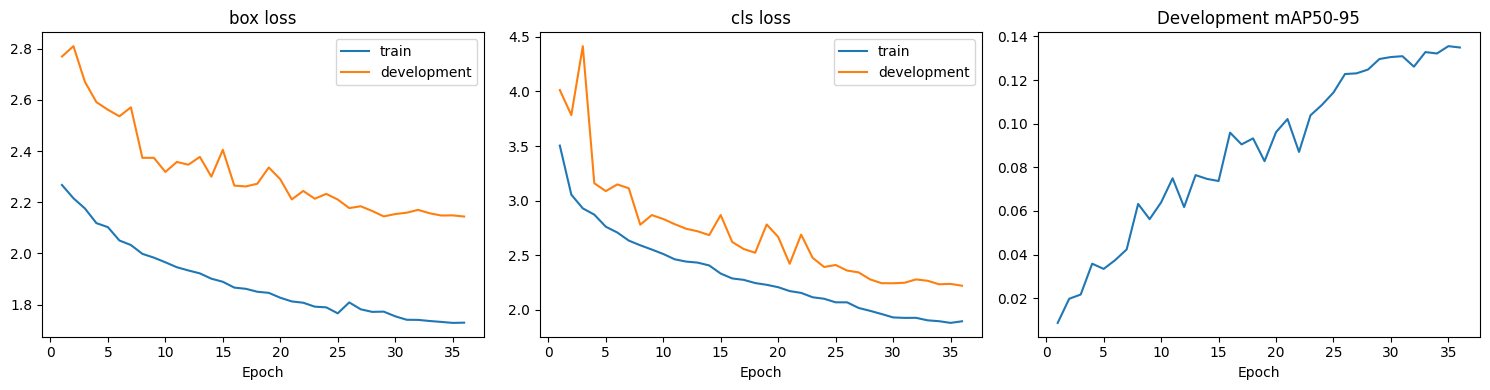

,epoch,train/box_loss,val/box_loss,metrics/mAP50(B),metrics/mAP50-95(B)
28,29,1.77302,2.14478,0.29668,0.12965
29,30,1.75477,2.15388,0.30199,0.13055
30,31,1.74121,2.15925,0.30258,0.13093
31,32,1.74075,2.17024,0.28700,0.12614
32,33,1.73641,2.15702,0.29903,0.13282
33,34,1.73290,2.14823,0.29972,0.13217
34,35,1.72905,2.14882,0.30309,0.13553
35,36,1.72988,2.14425,0.30564,0.13492


In [3]:
history = pd.read_csv(PREVIOUS / 'runs/E2_nano_standard/results.csv')
history.columns = history.columns.str.strip()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, component in zip(axes[:2], ['box', 'cls']):
    axis.plot(history.epoch, history[f'train/{component}_loss'], label='train')
    axis.plot(history.epoch, history[f'val/{component}_loss'], label='development')
    axis.set_title(component + ' loss')
    axis.set_xlabel('Epoch')
    axis.legend()
axes[2].plot(history.epoch, history['metrics/mAP50-95(B)'])
axes[2].set_title('Development mAP50-95')
axes[2].set_xlabel('Epoch')
fig.tight_layout()
fig.savefig(OUT / 'previous_training_curves.png', dpi=150)
plt.show()
display(history[['epoch', 'train/box_loss', 'val/box_loss',
                 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']].tail(8))


## 4. Use all eligible training blocks

The earlier run capped the training sample at 8,000 images. Here we use all valid images from the same training-eligible filename blocks. No image from a development/test block is moved into training. A 10-frame guard on each side of a 200-frame block is retained.

Filename blocks are capture-sequence proxies, not verified trip IDs. This limitation remains. We retain natural background prevalence and report class support; we do not remove difficult examples to inflate validation scores.

In [4]:
audit = pd.read_csv(PREVIOUS / 'data_audit.csv')
candidates = audit[audit.source_split == 'train'].copy()
candidates['path'] = candidates['path'].map(current_path)
candidates['label'] = candidates['label'].map(current_path)
candidates['block'] = candidates['frame'] // 200
candidates['bucket'] = [
    int(hashlib.sha256(f'{country}:{block}:42'.encode()).hexdigest()[:8], 16) % 10
    for country, block in zip(candidates.country, candidates.block)
]
inside_guard = (candidates['frame'] % 200).between(10, 189)
candidates = candidates[(candidates.bucket >= 4) & inside_guard].copy()
assert set(candidates.country) == {'Japan', 'India', 'Czech'}

reserved = pd.concat([in_dev[['path']], china_dev[['path']], locked_paths])
reserved = reserved.drop_duplicates('path').reset_index(drop=True)
assert set(candidates.path).isdisjoint(reserved.path)
print('Eligible training images before similarity screening:', len(candidates))
print('Earlier training images:', len(load_manifest('train')))


Eligible training images before similarity screening: 11171
Earlier training images: 7984


## 5. Screen cross-split image similarity

Check byte-identical files with SHA256 and visually similar files with perceptual hash. Scikit-learn nearest-neighbor search uses Hamming distance on the 64 hash bits. Training images at distance 4 or less from any reserved development/test image are excluded and logged. This uses image appearance only, not test labels or predictions. A perceptual hash is a practical screen, not proof that every correlated road scene has been removed.

In [5]:
def fingerprint(path):
    with Image.open(path) as image:
        bits = imagehash.phash(image.convert('RGB')).hash.reshape(-1)
    checksum = hashlib.sha256(Path(path).read_bytes()).hexdigest()
    return checksum, bits

reserved_paths = reserved.path.tolist()
training_paths = candidates.path.tolist()
with ThreadPoolExecutor(max_workers=8) as pool:
    reserved_hashes = list(pool.map(fingerprint, reserved_paths))
    training_hashes = list(pool.map(fingerprint, training_paths))

reserved_checksums = {checksum for checksum, _ in reserved_hashes}
reserved_bits = np.stack([bits for _, bits in reserved_hashes])
training_bits = np.stack([bits for _, bits in training_hashes])
search = NearestNeighbors(n_neighbors=1, metric='hamming', algorithm='brute', n_jobs=2)
search.fit(reserved_bits)
nearest_distance = []
for start in range(0, len(training_bits), 256):
    distance, _ = search.kneighbors(training_bits[start:start + 256])
    nearest_distance.extend(distance[:, 0] * 64)

exact_match = [checksum in reserved_checksums for checksum, _ in training_hashes]
candidates['nearest_reserved_hash_distance'] = nearest_distance
excluded = np.asarray(exact_match) | (np.asarray(nearest_distance) <= 4)
candidates[excluded].to_csv(OUT / 'excluded_similar_images.csv', index=False)
train = candidates[~excluded].reset_index(drop=True)
assert len(train) >= 8000, 'Too many exclusions; inspect data before training.'
assert (train[CLASSES].sum() > 20).all()
train.to_csv(OUT / 'train_manifest.csv', index=False)
for name, table in [('development', dev), ('in_domain_dev', in_dev), ('china_dev', china_dev)]:
    table.to_csv(OUT / (name + '_manifest.csv'), index=False)
print('Retained training images:', len(train), '| excluded:', int(excluded.sum()))
display(train.groupby('country').agg(images=('path', 'size'), boxes=('boxes', 'sum')))
display(train[CLASSES].sum().rename('images containing class').to_frame())
print('Background images:', int((train.boxes == 0).sum()))


Retained training images: 11149 | excluded: 22


,images,boxes
country,,
Czech,1271,783
India,4471,3916
Japan,5407,8531


,images containing class
D00,2423
D10,1335
D20,3474
D40,1655


Background images: 4766


## 6. Verify labels and prepare fast local training files

Check class IDs and normalized boxes on training/development annotations, then copy only those splits into temporary local storage. No test labels are copied. Local files reduce repeated remote reads during a long run. Source data stays unchanged, and temporary images are excluded from the final model package.

Inspect the ground-truth examples below. Drawn boxes should surround the labeled damage; a valid numeric label can still be a poor annotation.

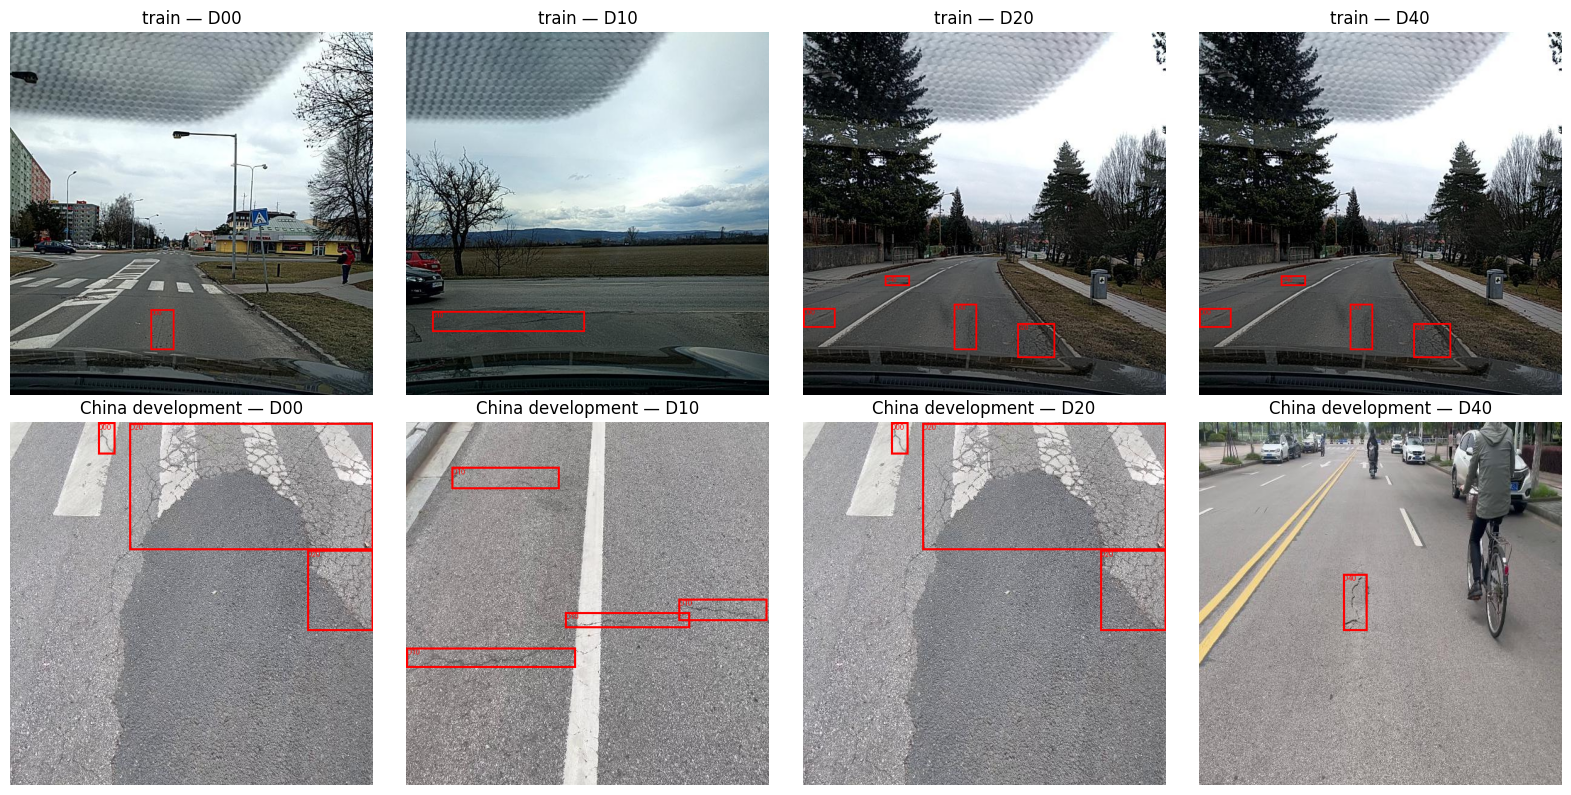

In [6]:
LOCAL = Path('/kaggle/temp/roadscan_v2_data')
tables = {'train': train, 'development': dev,
          'in_domain_dev': in_dev, 'china_dev': china_dev}

def copy_pair(item):
    split, image_path, label_path = item
    for line in Path(label_path).read_text().splitlines():
        if not line.strip():
            continue
        values = np.asarray(line.split(), dtype=float)
        assert len(values) == 5 and np.isfinite(values).all(), label_path
        category, x, y, width, height = values
        assert category == int(category) and 0 <= category < 4, label_path
        assert 0 <= x <= 1 and 0 <= y <= 1, label_path
        assert 0 < width <= 1 and 0 < height <= 1, label_path
    shutil.copy2(image_path, LOCAL / split / 'images' / Path(image_path).name)
    shutil.copy2(label_path, LOCAL / split / 'labels' / Path(label_path).name)

items = []
for split, table in tables.items():
    (LOCAL / split / 'images').mkdir(parents=True, exist_ok=True)
    (LOCAL / split / 'labels').mkdir(parents=True, exist_ok=True)
    items.extend((split, row.path, row.label) for row in table.itertuples())
with ThreadPoolExecutor(max_workers=8) as pool:
    list(pool.map(copy_pair, items))

YAMLS = {}
for split in ['development', 'in_domain_dev', 'china_dev']:
    config = {'path': str(LOCAL), 'train': 'train/images',
              'val': split + '/images', 'names': dict(enumerate(CLASSES))}
    path = OUT / (split + '.yaml')
    path.write_text(yaml.safe_dump(config))
    YAMLS[split] = str(path)
DATA = YAMLS['development']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, (split, table) in enumerate([('train', train), ('China development', china_dev)]):
    for category in range(4):
        example = table[table[CLASSES[category]] == 1].iloc[0]
        image = Image.open(example.path).convert('RGB')
        width, height = image.size
        draw = ImageDraw.Draw(image)
        for line in Path(example.label).read_text().splitlines():
            if not line.strip():
                continue
            c, x, y, w, h = map(float, line.split())
            box = [(x-w/2)*width, (y-h/2)*height, (x+w/2)*width, (y+h/2)*height]
            draw.rectangle(box, outline='red', width=3)
            draw.text(box[:2], CLASSES[int(c)], fill='red')
        axes[row, category].imshow(image)
        axes[row, category].set_title(split + ' — ' + CLASSES[category])
        axes[row, category].axis('off')
fig.tight_layout()
fig.savefig(OUT / 'annotation_examples.jpg', dpi=140)
plt.show()


## 7. Train YOLO26s with a fixed schedule

YOLO26s is a supported pretrained detector, with more capacity than the previous nano model. A 768-pixel input gives small defects more detail than 640, at higher compute cost. It is a candidate, not an assumed winner.

AdamW, weight decay, moderate appearance augmentation, horizontal flips and early stopping are used. Vertical flips and extreme perspective changes are excluded. Mosaic is reduced and disabled during the last 15 planned epochs. We do not add classification-only dropout or edit the detector's loss implementation. Best checkpoints are selected by development mAP50–95; training loss is not the selection metric.

In [7]:
common = dict(
    data=DATA,
    device=0,
    workers=2,
    seed=SEED,
    deterministic=True,
    optimizer='AdamW',
    weight_decay=0.0005,
    warmup_bias_lr=0.0,
    cos_lr=True,
    fliplr=0.5,
    flipud=0.0,
    degrees=0.0,
    perspective=0.0,
    mixup=0.0,
    cache=False,
    amp=True,
    save=True,
    save_period=10,
    plots=True,
    nms=True,
    project=str(OUT / 'runs')
)
main_settings = dict(
    epochs=EPOCHS, patience=20, imgsz=TRAIN_SIZE, batch=BATCH,
    lr0=0.001, lrf=0.05, warmup_epochs=3,
    mosaic=0.5, close_mosaic=15, hsv_s=0.5, hsv_v=0.3,
    translate=0.1, scale=0.4, name='yolo26s_768'
)
(OUT / 'training_plan.json').write_text(json.dumps({
    'common': common, 'main': main_settings,
    'fine_tune_epochs': FINETUNE_EPOCHS, 'target_mAP50': TARGET_MAP50,
    'selection': 'highest worst-domain development mAP50-95, then domain mean',
    'test_policy': 'Do not evaluate or tune on USA, previous in-domain test, or local test.'
}, indent=2))

model = YOLO('yolo26s.pt')
model.train(**common, **main_settings)
main_run = Path(model.trainer.save_dir)
main_best = main_run / 'weights/best.pt'
assert main_best.is_file()
(OUT / 'phase1_checkpoint.txt').write_text(str(main_best))
print('Phase 1 saved:', main_best)
del model
gc.collect()
torch.cuda.empty_cache()


New https://pypi.org/project/ultralytics/8.4.178 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/roadscan_v2/development.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=90, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=768, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo2

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/90      4.27G      2.106      3.533    0.02287         10        768: 100% ━━━━━━━━━━━━ 1394/1394 5.9it/s 3:55
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 5.9it/s 10.6s
                   all       1000       1743      0.401      0.155     0.0959     0.0321

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/90      4.27G      2.117      3.337    0.02344          7        768: 100% ━━━━━━━━━━━━ 1394/1394 6.0it/s 3:54
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 5.9it/s 10.6s
                   all       1000       1743      0.421       0.16      0.102     0.0353

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/90      4.27G      2.075      3.266    0.02245          7        768: 100% ━━━━━━━━━━━━ 1394/1394 6.0it/s 3:54
                 Class     Images  Instances    

## 8. Fine-tune at higher resolution

Start from phase 1's best weights, not from random initialization. Use a lower learning rate, smaller geometric/colour changes and no Mosaic. This tests whether more image detail improves localization after the detector has learned the task. The result will be compared with phase 1 and the previous detector on the same development images at the same evaluation resolution; a worse fine-tune is not automatically adopted.

In [8]:
fine_settings = dict(
    epochs=FINETUNE_EPOCHS, patience=8, imgsz=EVAL_SIZE, batch=4,
    lr0=0.0001, lrf=0.1, warmup_epochs=1,
    mosaic=0.0, close_mosaic=0, hsv_s=0.3, hsv_v=0.2,
    translate=0.05, scale=0.15, name='yolo26s_960_finetune'
)
model = YOLO(str(main_best))
model.train(**common, **fine_settings)
fine_run = Path(model.trainer.save_dir)
fine_best = fine_run / 'weights/best.pt'
assert fine_best.is_file()
(OUT / 'phase2_checkpoint.txt').write_text(str(fine_best))
print('Phase 2 saved:', fine_best)
del model
gc.collect()
torch.cuda.empty_cache()


New https://pypi.org/project/ultralytics/8.4.178 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/roadscan_v2/development.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggl

## 9. Compare candidates on development only

Evaluate three predeclared candidates: previous YOLO11n, phase-1 YOLO26s and high-resolution fine-tune. Every candidate uses 960 pixels, the same NMS head policy, and the same in-domain/China development images. Save AP, precision and recall for every damage class.

Select by the lower of the two domain mAP50–95 values; use the domain mean only to break ties. This discourages a gain on familiar roads that hides a regression on the unseen development country. The previous model remains a valid candidate. There is no instruction to force the new model to win or to stop reporting a weak class.

In [9]:
candidates_to_score = {
    'previous_yolo11n': str(old_checkpoint),
    'yolo26s_768': str(main_best),
    'yolo26s_960_finetune': str(fine_best)
}
rows = []
class_rows = []
for name, checkpoint in candidates_to_score.items():
    detector = YOLO(checkpoint)
    for domain in ['in_domain_dev', 'china_dev']:
        metrics = detector.val(
            data=YAMLS[domain], imgsz=EVAL_SIZE, batch=4,
            device=0, workers=2, nms=True, plots=True,
            project=str(OUT / 'development_evaluation'), name=name + '_' + domain
        )
        rows.append(dict(candidate=name, domain=domain, checkpoint=checkpoint,
                         mAP50=float(metrics.box.map50), mAP50_95=float(metrics.box.map)))
        for index, class_id in enumerate(metrics.box.ap_class_index):
            precision, recall, ap50, ap = metrics.box.class_result(index)
            class_rows.append(dict(candidate=name, domain=domain,
                class_name=CLASSES[int(class_id)], precision=float(precision),
                recall=float(recall), AP50=float(ap50), AP50_95=float(ap)))
        pd.DataFrame(rows).to_csv(OUT / 'development_results.csv', index=False)
        pd.DataFrame(class_rows).to_csv(OUT / 'development_by_class.csv', index=False)
    del detector
    gc.collect()
    torch.cuda.empty_cache()

results = pd.DataFrame(rows)
ranking = results.groupby('candidate').agg(
    worst_domain_AP=('mAP50_95', 'min'), mean_domain_AP=('mAP50_95', 'mean'),
    worst_domain_AP50=('mAP50', 'min')
).sort_values(['worst_domain_AP', 'mean_domain_AP'], ascending=False)
winner = ranking.index[0]
WINNER = candidates_to_score[winner]
ranking.to_csv(OUT / 'candidate_ranking.csv')
(OUT / 'selection.json').write_text(json.dumps(dict(
    candidate=winner, checkpoint=WINNER,
    criterion='worst-domain development mAP50-95, then mean; no test metrics',
    target_mAP50=TARGET_MAP50,
    development_target_met=bool(ranking.loc[winner, 'worst_domain_AP50'] >= TARGET_MAP50)
), indent=2))
display(results)
display(ranking)
print('Development-selected candidate:', winner)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1482.2±302.6 MB/s, size: 61.5 KB)
val: Scanning /kaggle/temp/roadscan_v2_data/in_domain_dev/labels... 1000 images, 358 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.3Kit/s 0.7s
val: New cache created: /kaggle/temp/roadscan_v2_data/in_domain_dev/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 17.3it/s 14.5s
                   all       1000       1260       0.44      0.413      0.374      0.153
                   D00        250        348      0.399      0.382      0.336      0.149
                   D10        153        250      0.348      0.328      0.233     0.0784
                   D20        349        451      0.586       0.58      0.576      0.236
                   D40        

,candidate,domain,checkpoint,mAP50,mAP50_95
0,previous_yolo11n,in_domain_dev,/kaggle/input/notebooks/rimasabunasser/05-road...,0.374321,0.153495
1,previous_yolo11n,china_dev,/kaggle/input/notebooks/rimasabunasser/05-road...,0.108349,0.027583
2,yolo26s_768,in_domain_dev,/kaggle/working/roadscan_v2/runs/yolo26s_768/w...,0.510583,0.236198
3,yolo26s_768,china_dev,/kaggle/working/roadscan_v2/runs/yolo26s_768/w...,0.226610,0.079941
4,yolo26s_960_finetune,in_domain_dev,/kaggle/working/roadscan_v2/runs/yolo26s_960_f...,0.501133,0.236937
5,yolo26s_960_finetune,china_dev,/kaggle/working/roadscan_v2/runs/yolo26s_960_f...,0.212431,0.078994


,worst_domain_AP,mean_domain_AP,worst_domain_AP50
candidate,,,
yolo26s_768,0.079941,0.158069,0.226610
yolo26s_960_finetune,0.078994,0.157966,0.212431
previous_yolo11n,0.027583,0.090539,0.108349


Development-selected candidate: yolo26s_768


## 10. Calibrate confidence and inspect precision/recall

Choose one confidence threshold from the development F1 curve. Then count true positives, false positives and missed boxes at IoU 0.5, using class-correct, one-to-one matches. This shows the operating trade-off explicitly. mAP is not accuracy, and a high precision obtained by predicting almost nothing is not acceptable evidence of quality. These are development estimates, not a blind test.

Prediction lists contain at most four images. This explicitly avoids the previous whole-list GPU-memory failure.

In [10]:
detector = YOLO(WINNER)
calibration = detector.val(
    data=DATA, imgsz=EVAL_SIZE, batch=4, device=0, workers=2,
    nms=True, plots=True, project=str(OUT / 'calibration'), name='selected'
)
CONFIDENCE = None
for title, curve in zip(calibration.curves, calibration.curves_results):
    if 'F1' in title:
        x = np.asarray(curve[0])
        y = np.asarray(curve[1])
        mean_f1 = y.mean(axis=0) if y.ndim == 2 else y
        CONFIDENCE = float(x[np.argmax(mean_f1)])
        break
assert CONFIDENCE is not None, 'F1 curve unavailable; inspect calibration output.'
print('Development confidence:', CONFIDENCE)

def truth_boxes(image_path):
    label = Path(image_path).parent.parent / 'labels' / (Path(image_path).stem + '.txt')
    with Image.open(image_path) as image:
        width, height = image.size
    boxes, classes = [], []
    for line in label.read_text().splitlines():
        if line.strip():
            c, x, y, w, h = map(float, line.split())
            boxes.append([(x-w/2)*width, (y-h/2)*height, (x+w/2)*width, (y+h/2)*height])
            classes.append(int(c))
    return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), np.array(classes)

counts = np.zeros((4, 3), dtype=int)  # columns: true positive, false positive, false negative
paths = sorted((LOCAL / 'development/images').glob('*.jpg'))
for start in range(0, len(paths), 4):
    chunk = [str(path) for path in paths[start:start + 4]]
    predictions = detector.predict(chunk, imgsz=EVAL_SIZE, conf=CONFIDENCE,
                                   device=0, nms=True, stream=True, verbose=False)
    for prediction in predictions:
        truth, truth_classes = truth_boxes(prediction.path)
        boxes = prediction.boxes.xyxy.cpu()
        classes = prediction.boxes.cls.cpu().numpy().astype(int)
        scores = prediction.boxes.conf.cpu().numpy()
        overlaps = box_iou(truth, boxes).numpy()
        matched = set()
        for index in np.argsort(-scores):
            category = classes[index]
            choices = [g for g in range(len(truth_classes)) if g not in matched
                       and truth_classes[g] == category and overlaps[g, index] >= 0.5]
            if choices:
                best_match = max(choices, key=lambda g: overlaps[g, index])
                matched.add(best_match)
                counts[category, 0] += 1
            else:
                counts[category, 1] += 1
        for index, category in enumerate(truth_classes):
            if index not in matched:
                counts[category, 2] += 1

operating = pd.DataFrame(counts, columns=['TP', 'FP', 'FN'], index=CLASSES)
operating['precision'] = operating.TP / (operating.TP + operating.FP).clip(lower=1)
operating['recall'] = operating.TP / (operating.TP + operating.FN).clip(lower=1)
operating['F1'] = 2 * operating.TP / (2*operating.TP + operating.FP + operating.FN).clip(lower=1)
operating.to_csv(OUT / 'development_operating_metrics.csv')
display(operating)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1659.6±548.4 MB/s, size: 59.4 KB)
val: Scanning /kaggle/temp/roadscan_v2_data/development/labels.cache... 1000 images, 199 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 349.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 9.0it/s 27.7s
                   all       1000       1743      0.451      0.409      0.361      0.152
                   D00        473        830      0.438      0.264      0.248      0.101
                   D10        255        389      0.381      0.422      0.329      0.109
                   D20        283        374      0.631      0.545      0.568      0.264
                   D40        102        150      0.354      0.407      0.301      0.134
Speed: 1.9ms pre

,TP,FP,FN,precision,recall,F1
D00,177,216,653,0.450382,0.213253,0.289452
D10,141,208,248,0.404011,0.362468,0.382114
D20,200,124,174,0.617284,0.534759,0.573066
D40,61,86,89,0.414966,0.406667,0.410774


## 11. Check the train/development gap and visual predictions

A fixed training probe is a diagnostic, not an independent score. Compare it with in-domain development and China development; gaps can reflect both memorization and domain shift. Plot both phase histories and show development predictions next to ground truth. Early stopping, weight decay and augmentation reduce risk; none proves the absence of overfitting.

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1817.4±610.9 MB/s, size: 71.5 KB)
val: Scanning /kaggle/temp/roadscan_v2_data/train/labels... 500 images, 208 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 1.3Kit/s 0.4s
val: New cache created: /kaggle/temp/roadscan_v2_data/train/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 9.6it/s 13.0s
                   all        500        623      0.687      0.684      0.736      0.387
                   D00        107        146      0.673       0.62       0.67       0.34
                   D10         67        124      0.606      0.653      0.685      0.318
                   D20        164        214      0.757        0.8      0.841      0.502
                   D40         71        139     

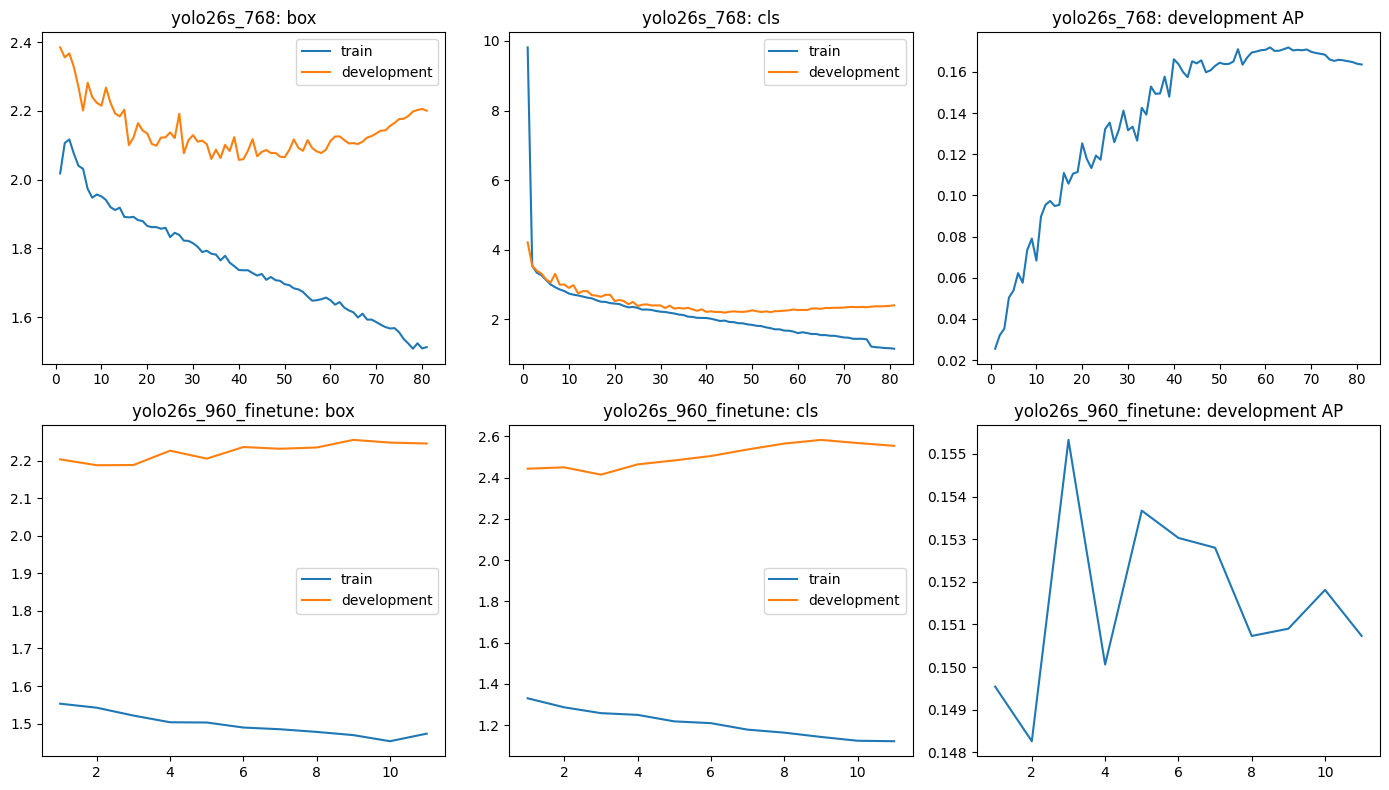

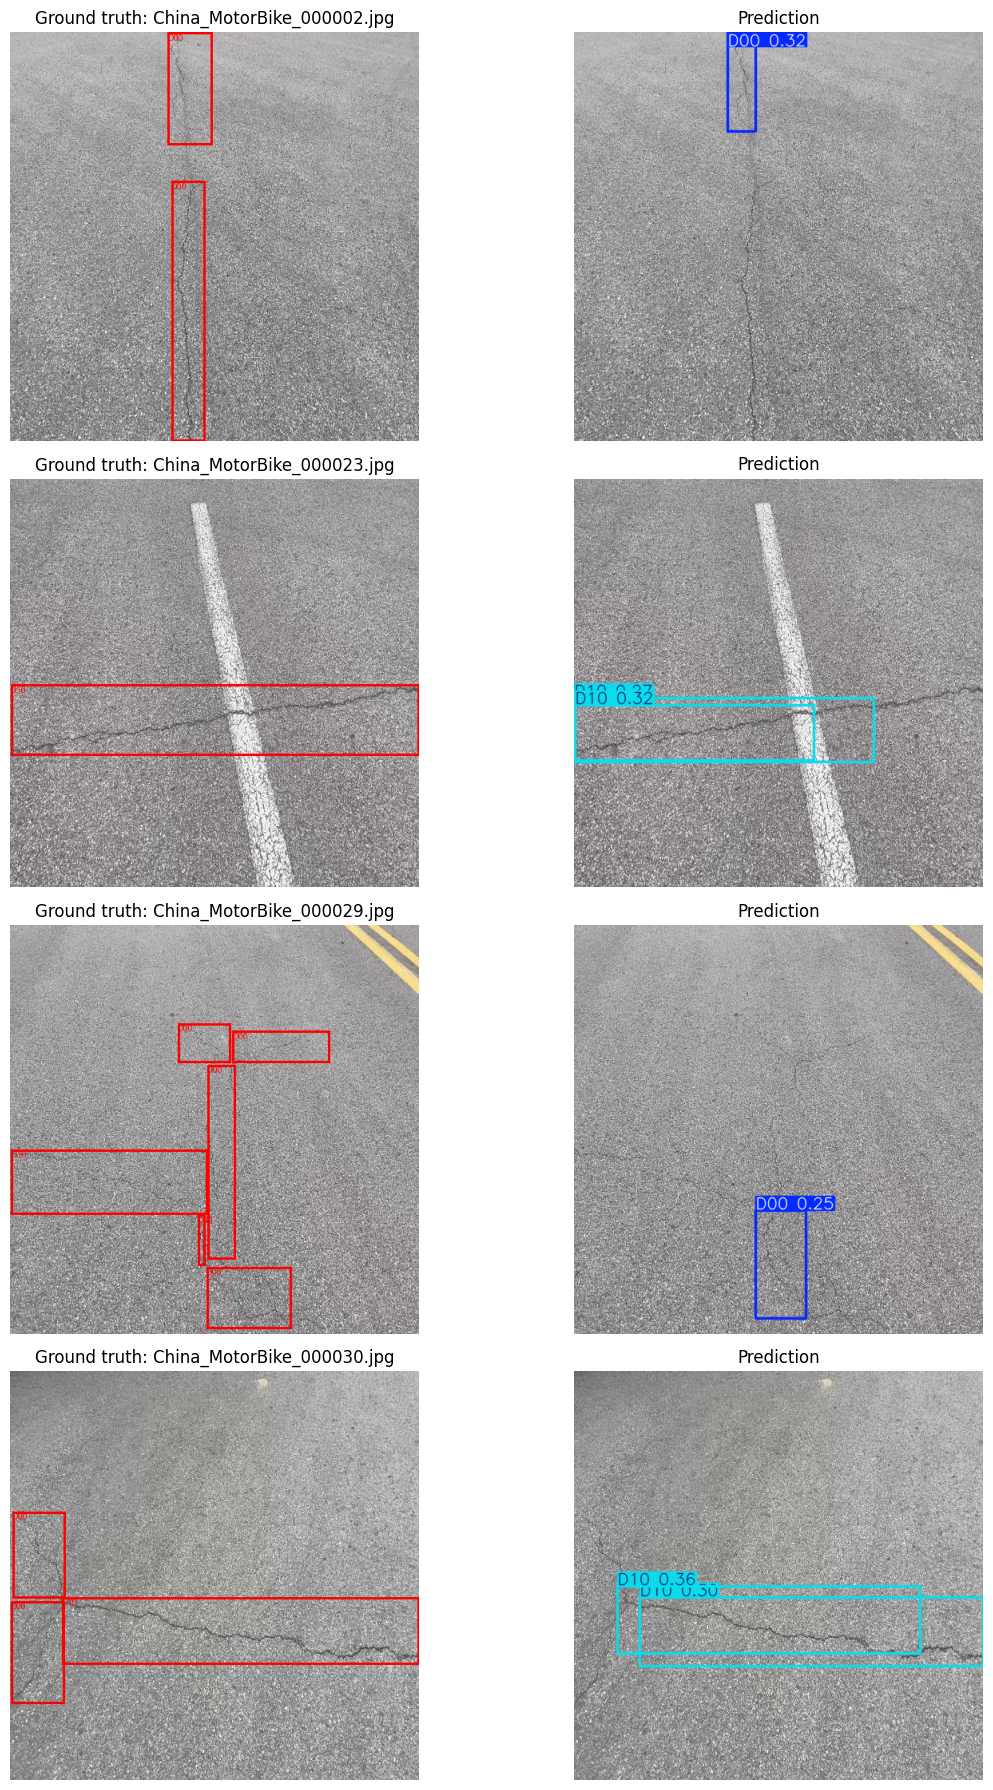

In [11]:
probe = train.sample(n=min(500, len(train)), random_state=SEED)
probe_list = OUT / 'training_probe.txt'
probe_list.write_text(chr(10).join(
    str(LOCAL / 'train/images' / Path(path).name) for path in probe.path
))
probe_yaml = yaml.safe_load(Path(DATA).read_text())
probe_yaml['val'] = str(probe_list)
probe_config = OUT / 'training_probe.yaml'
probe_config.write_text(yaml.safe_dump(probe_yaml))
probe_metrics = detector.val(data=str(probe_config), imgsz=EVAL_SIZE,
    batch=4, device=0, workers=2, nms=True, plots=False)
(OUT / 'training_gap_diagnostic.json').write_text(json.dumps(dict(
    images=len(probe), train_probe_AP50=float(probe_metrics.box.map50),
    train_probe_AP=float(probe_metrics.box.map),
    warning='Training probe is not independent; inspect both domain gaps and curves.'
), indent=2))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, run in enumerate([main_run, fine_run]):
    table = pd.read_csv(run / 'results.csv')
    table.columns = table.columns.str.strip()
    for col, component in enumerate(['box', 'cls']):
        axes[row, col].plot(table.epoch, table[f'train/{component}_loss'], label='train')
        axes[row, col].plot(table.epoch, table[f'val/{component}_loss'], label='development')
        axes[row, col].set_title(run.name + ': ' + component)
        axes[row, col].legend()
    axes[row, 2].plot(table.epoch, table['metrics/mAP50-95(B)'])
    axes[row, 2].set_title(run.name + ': development AP')
fig.tight_layout()
fig.savefig(OUT / 'training_curves.png', dpi=150)
plt.show()

fig, axes = plt.subplots(4, 2, figsize=(13, 18))
for index, path in enumerate(paths[:4]):
    image = Image.open(path).convert('RGB')
    boxes, categories = truth_boxes(str(path))
    draw = ImageDraw.Draw(image)
    for box, category in zip(boxes.tolist(), categories):
        draw.rectangle(box, outline='red', width=3)
        draw.text(box[:2], CLASSES[category], fill='red')
    prediction = detector.predict(str(path), imgsz=EVAL_SIZE,
        conf=CONFIDENCE, device=0, nms=True, verbose=False)[0]
    axes[index, 0].imshow(image)
    axes[index, 0].set_title('Ground truth: ' + path.name)
    axes[index, 1].imshow(prediction.plot()[..., ::-1])
    axes[index, 1].set_title('Prediction')
    for axis in axes[index]:
        axis.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'development_predictions.jpg', dpi=130)
plt.show()


## 12. Package the selected model and verify a fresh load

Save weights, class order, image size, confidence and dependencies. A small inference script is executed in a new Python process on CPU. We declare the package usable only if that process succeeds. The report includes unsuccessful targets and remaining evidence, not just the winning score. USA, the former in-domain test and local data are not evaluated here.

In [12]:
bundle = OUT / 'model_bundle'
bundle.mkdir(exist_ok=True)
shutil.copy2(WINNER, bundle / 'best.pt')
model_config = dict(
    classes=CLASSES, image_size=EVAL_SIZE, confidence=CONFIDENCE, nms=True,
    candidate=winner, ultralytics='8.4.177', local_test='PENDING',
    selection='Development only; prior external test scores have historical exposure.'
)
(bundle / 'config.json').write_text(json.dumps(model_config, indent=2))
(bundle / 'requirements.txt').write_text('ultralytics==8.4.177\n')
inference_code = """from pathlib import Path
import argparse
import json
from ultralytics import YOLO

parser = argparse.ArgumentParser()
parser.add_argument('--image', required=True)
args = parser.parse_args()
root = Path(__file__).resolve().parent
config = json.loads((root / 'config.json').read_text())
model = YOLO(str(root / 'best.pt'))
results = model.predict(args.image, imgsz=config['image_size'],
    conf=config['confidence'], nms=config['nms'], device='cpu', verbose=False)
print('Fresh-process prediction succeeded:', len(results))
"""
(bundle / 'predict.py').write_text(inference_code)
fresh_load = subprocess.run(
    [sys.executable, str(bundle / 'predict.py'), '--image', str(paths[0])],
    capture_output=True, text=True, timeout=180
)
(OUT / 'fresh_load_test.txt').write_text(fresh_load.stdout + fresh_load.stderr)
assert fresh_load.returncode == 0, 'Fresh-process inference failed; inspect its log.'
print(fresh_load.stdout)

report = [
    '# RoadScan improvement report',
    '## Development-only selection', ranking.to_markdown(),
    '## Domain metrics', results.to_markdown(index=False),
    '## Per-class metrics', pd.DataFrame(class_rows).to_markdown(index=False),
    '## Operating point', operating.to_markdown(),
    '## Interpretation',
    'The 92% mAP50 target is aspirational. Target met on BOTH development domains: '
        + str(bool(ranking.loc[winner, 'worst_domain_AP50'] >= TARGET_MAP50)),
    'Development selection is optimistic and does not establish blind-test performance.',
    'This pipeline changes data volume, architecture, resolution and schedule together; '
        'it is not an architecture-only ablation.',
    'No new USA or former in-domain test scores were used. Previous scores were already '
        'viewed, so a new independent local Saudi test is needed.',
    'Filename blocks and perceptual hashes reduce leakage risk but cannot prove '
        'trip separation. No guarantee of zero overfitting or worldwide generalization.',
    'Training/development curves, per-class recall and representative failures must be '
        'reviewed before deployment.',
    '## Reuse', 'python model_bundle/predict.py --image /path/to/road.jpg',
    'Fresh-process CPU inference passed. Local annotated evaluation: PENDING.'
]
(OUT / 'REPORT.md').write_text(chr(10).join(report))
(bundle / 'MODEL_CARD.md').write_text(chr(10).join(report[-11:]))
checksums = {str(path.relative_to(bundle)): hashlib.sha256(path.read_bytes()).hexdigest()
             for path in bundle.iterdir() if path.is_file()}
(bundle / 'SHA256.json').write_text(json.dumps(checksums, indent=2))
shutil.make_archive('/kaggle/working/roadscan_model', 'zip', root_dir=bundle)
print('MODEL PACKAGE: /kaggle/working/roadscan_model.zip')
print('REPORT:', OUT / 'REPORT.md')


Fresh-process prediction succeeded: 1

MODEL PACKAGE: /kaggle/working/roadscan_model.zip
REPORT: /kaggle/working/roadscan_v2/REPORT.md
